# Dirac Operator 고유값 분포

KrylovKit (Arnoldi method)로 **D 자체**의 고유값을 복소 평면에서 계산합니다.

- D는 non-hermitian → 고유값은 **복소수**
- Arnoldi iteration으로 |λ|가 작은 고유값을 반복적으로 계산
- 행렬을 명시적으로 구성하지 않음 (행렬-벡터 곱 D·x만 사용)

In [1]:
using LatticeDiracOperators
using Gaugefields
using LMP
using LinearAlgebra
using Plots
using JLD2
using KrylovKit

NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
NC = 3

params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.15
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 1

Ndof = NC * NX * NY * NZ * NT * 4
println("Lattice: $(NX)×$(NY)×$(NZ)×$(NT), DOF = $Ndof")
println("KrylovKit iterative eigensolver — 행렬 저장 불필요")

┌ Warning: Circular dependency detected. Precompilation will be skipped for:
│   ChainRules [082447d4-558c-5d27-93f4-14fc19e9eca2]
│   SpecialFunctionsExt [1285c0f1-ff9f-5867-b66e-0f359bcf09ba]
│   GPUArrays [0c68f7d7-f131-5f86-a1c3-88cf8149b2d7]
│   LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
│   KernelAbstractions [63c18a36-062a-441e-b654-da1e3ab1ce7c]
│   CUDA [052768ef-5323-5732-b1bb-66c8b64840ba]
│   SparseArraysExt [85068d23-b5fb-53f1-8204-05c2aba6942f]
│   StructArraysGPUArraysCoreExt [cbbf52aa-d660-55d4-8a5a-33845bbaa85d]
│   AtomixCUDAExt [13011619-4c7c-5ef0-948f-5fc81565cd05]
│   LinearAlgebraExt [66d79d19-2cc4-5b0b-ac7a-b340256d1ecd]
│   ZygoteColorsExt [e68c091a-8ea5-5ca7-be4f-380657d4ad79]
│   ChainRulesCoreExt [eae2faf6-b232-58cb-a410-7764fda2830c]
│   Zygote [e88e6eb3-aa80-5325-afca-941959d7151f]
└ @ Pkg.API C:\Users\_s2220186\AppData\Local\Programs\Julia-1.10.7\share\julia\stdlib\v1.10\Pkg\src\API.jl:1279
[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ 

Lattice: 8×8×8×16, DOF = 98304
KrylovKit iterative eigensolver — 행렬 저장 불필요

## WilsonFermion ↔ Vector 변환 및 D eigensolver

KrylovKit는 일반 `Vector`에서 동작하므로 WilsonFermion ↔ flat Vector 변환이 필요합니다.

In [2]:
# WilsonFermion → flat Vector{ComplexF64}
function wf_to_vec(x)
    NX=x.NX; NY=x.NY; NZ=x.NZ; NT=x.NT; NC=x.NC; NG=4
    v = Vector{ComplexF64}(undef, NC*NX*NY*NZ*NT*NG)
    idx = 0
    for ig=1:NG, it=1:NT, iz=1:NZ, iy=1:NY, ix=1:NX, ic=1:NC
        idx += 1
        @inbounds v[idx] = x[ic,ix,iy,iz,it,ig]
    end
    return v
end

# flat Vector → WilsonFermion
function vec_to_wf!(x, v)
    NX=x.NX; NY=x.NY; NZ=x.NZ; NT=x.NT; NC=x.NC; NG=4
    idx = 0
    for ig=1:NG, it=1:NT, iz=1:NZ, iy=1:NY, ix=1:NX, ic=1:NC
        idx += 1
        @inbounds x[ic,ix,iy,iz,it,ig] = v[idx]
    end
    return x
end

"""
    compute_D_eigenvalues(D, U, nev; krylovdim, tol)

D의 Re(λ)가 가장 작은 고유값 nev개를 Arnoldi로 계산.
D는 non-hermitian → 고유값은 복소수.
Returns (eigenvalues::Vector{ComplexF64}, eigenvectors)
"""
function compute_D_eigenvalues(D, U, nev::Int;
        krylovdim=max(2nev+20, 50), tol=1e-8, maxiter=500)
    
    x_buf = Initialize_pseudofermion_fields(U[1], "Wilson", nowing=true)
    y_buf = similar(x_buf)
    
    # D를 flat vector에 적용
    function D_matvec(v::Vector{ComplexF64})
        vec_to_wf!(x_buf, v)
        mul!(y_buf, D, x_buf)
        return wf_to_vec(y_buf)
    end
    
    Ndof = x_buf.NC * x_buf.NX * x_buf.NY * x_buf.NZ * x_buf.NT * 4
    x0 = randn(ComplexF64, Ndof)
    x0 ./= norm(x0)
    
    # Arnoldi: non-hermitian, :SR = smallest real part
    vals, vecs, info = eigsolve(D_matvec, x0, nev, :SR;
        issymmetric=false, ishermitian=false,
        krylovdim=krylovdim, tol=tol, maxiter=maxiter)
    
    println("KrylovKit: $(info.converged) converged, $(info.numiter) iterations, $(info.numops) matvecs")
    n = min(nev, length(vals))
    return vals[1:n], vecs[1:n]
end

println("Functions defined.")

Functions defined.


## 게이지 설정 로드 및 D 고유값 계산

In [3]:
nev = 50  # 구할 고유값 개수 (|λ| 작은 순서)

# 여러 게이지 배위에서 고유값 수집
gauge_files = ["C://Users/_s2220186/Desktop/Julia/gauge/config_$i.jld2" for i in 1:5]
all_evals = Vector{Vector{ComplexF64}}()

for (idx, gfile) in enumerate(gauge_files)
    println("=== Config $idx: $gfile ===")
    Ug = load(gfile, "U")
    U = Initialize_Gaugefields(NC, Nwing, NX, NY, NZ, NT, condition="cold")
    substitute_U!(U, Ug)
    
    x = Initialize_pseudofermion_fields(U[1], "Wilson", nowing=true)
    D_W = Dirac_operator(U, x, params)
    
    @time evals, _ = compute_D_eigenvalues(D_W, U, nev)
    push!(all_evals, evals)
    
    println("  |λ| 최소 5개: ", round.(abs.(evals[1:min(5,end)]), digits=8))
    println("  λ 최소 5개: ", round.(evals[1:min(5,end)], digits=6))
    println()
end

=== Config 1: C://Users/_s2220186/Desktop/Julia/gauge/config_1.jld2 ===
KrylovKit: 52 converged, 55 iterations, 1952 matvecs
115.731937 seconds (12.41 M allocations: 13.510 GiB, 1.83% gc time, 5.63% compilation time)
  |λ| 최소 5개: [0.05244673, 0.05244673, 0.05740764, 0.05740764, 0.05584373]
  λ 최소 5개: ComplexF64[-0.028499 - 0.044028im, -0.028499 + 0.044028im, -0.028206 - 0.05im, -0.028206 + 0.05im, -0.027989 - 0.048323im]

=== Config 2: C://Users/_s2220186/Desktop/Julia/gauge/config_2.jld2 ===
KrylovKit: 50 converged, 38 iterations, 1473 matvecs
 73.997256 seconds (95.14 k allocations: 9.011 GiB, 1.55% gc time, 0.00% compilation time)
  |λ| 최소 5개: [0.05857801, 0.05857801, 0.03165713, 0.03165713, 0.05017848]
  λ 최소 5개: ComplexF64[-0.008803 - 0.057913im, -0.008803 + 0.057913im, -0.008647 + 0.030453im, -0.008647 - 0.030453im, -0.008634 - 0.04943im]

=== Config 3: C://Users/_s2220186/Desktop/Julia/gauge/config_3.jld2 ===
KrylovKit: 52 converged, 43 iterations, 1630 matvecs
 80.990208 second

## D 고유값 분포 — 복소 평면

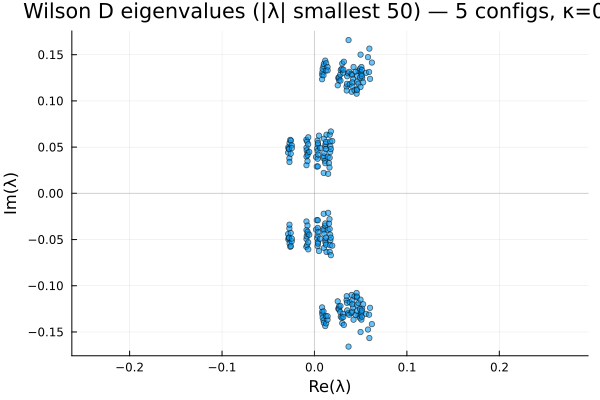

In [4]:
# 모든 config의 D 고유값을 복소 평면에 scatter
all_flat = vcat(all_evals...)

p1 = scatter(real.(all_flat), imag.(all_flat),
    markersize=3, alpha=0.6, legend=false,
    xlabel="Re(λ)", ylabel="Im(λ)",
    title="Wilson D eigenvalues (|λ| smallest $nev) — $(length(gauge_files)) configs, κ=$(params["κ"])",
    aspect_ratio=:equal)
vline!([0], color=:gray, linewidth=1, alpha=0.3)
hline!([0], color=:gray, linewidth=1, alpha=0.3)
display(p1)

## |λ| 분포 히스토그램

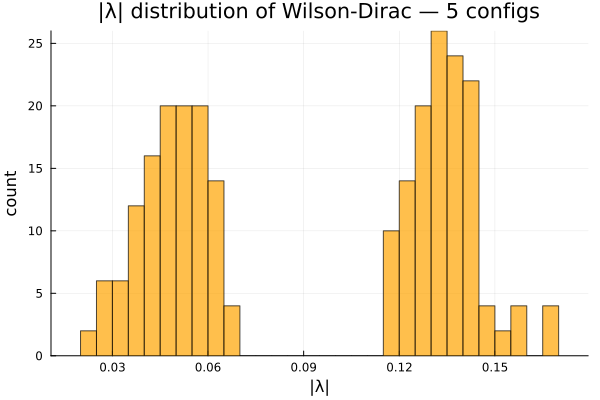

In [5]:
abs_vals = abs.(all_flat)

p2 = histogram(abs_vals, bins=60, alpha=0.7, legend=false, color=:orange,
    xlabel="|λ|", ylabel="count",
    title="|λ| distribution of Wilson-Dirac — $(length(gauge_files)) configs")
display(p2)

## Config별 고유값 비교 (복소 평면)

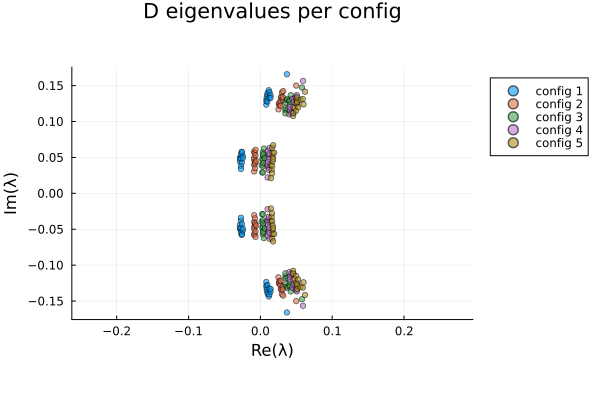

In [6]:
# 각 config의 고유값을 복소 평면에서 비교
p3 = plot(xlabel="Re(λ)", ylabel="Im(λ)",
    title="D eigenvalues per config", legend=:outertopright, aspect_ratio=:equal)
for (i, ev) in enumerate(all_evals)
    scatter!(real.(ev), imag.(ev), markersize=3, alpha=0.6, label="config $i")
end
display(p3)

## Wilson vs Clover 비교

In [7]:
# 1개 config에서 Wilson vs Clover 비교
Ug = load(gauge_files[1], "U")
U_cmp = Initialize_Gaugefields(NC, Nwing, NX, NY, NZ, NT, condition="cold")
substitute_U!(U_cmp, Ug)

x_cmp = Initialize_pseudofermion_fields(U_cmp[1], "Wilson", nowing=true)
D_W_cmp = Dirac_operator(U_cmp, x_cmp, params)

# Wilson D eigenvalues
println("Wilson D eigenvalues...")
@time evals_wilson, _ = compute_D_eigenvalues(D_W_cmp, U_cmp, nev)

# Clover D eigenvalues
D_cl = CloverDiracOperator(D_W_cmp, U_cmp, 1.0)

x_buf_cl = Initialize_pseudofermion_fields(U_cmp[1], "Wilson", nowing=true)
y_buf_cl = similar(x_buf_cl)

function D_clover_matvec(v::Vector{ComplexF64})
    vec_to_wf!(x_buf_cl, v)
    mul!(y_buf_cl, D_cl, x_buf_cl)
    return wf_to_vec(y_buf_cl)
end

Ndof_c = NC * NX * NY * NZ * NT * 4
x0_c = randn(ComplexF64, Ndof_c); x0_c ./= norm(x0_c)

println("Clover D eigenvalues...")
@time vals_cl, vecs_cl, info_cl = eigsolve(D_clover_matvec, x0_c, nev, :SR;
    issymmetric=false, ishermitian=false,
    krylovdim=max(2nev+20, 50), tol=1e-8, maxiter=500)
evals_clover = vals_cl[1:min(nev, length(vals_cl))]
println("Clover converged: $(info_cl.converged)")

Wilson D eigenvalues...
KrylovKit: 52 converged, 54 iterations, 1916 matvecs
 91.249585 seconds (127.65 k allocations: 12.487 GiB, 1.75% gc time, 0.00% compilation time)
Clover D eigenvalues...
 57.164739 seconds (204.86 k allocations: 7.275 GiB, 1.66% gc time, 0.41% compilation time)
Clover converged: 50


## Wilson vs Clover — D 고유값 비교 (복소 평면)

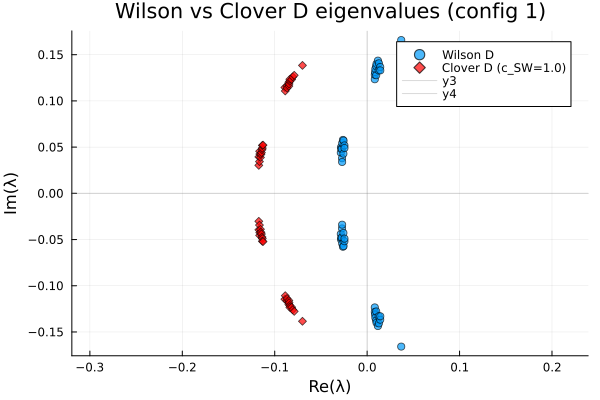

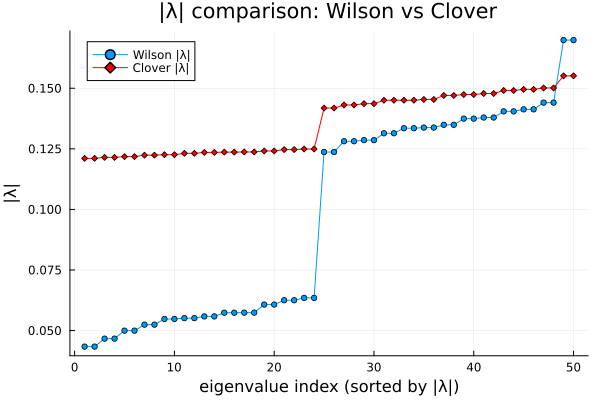

In [8]:
# 복소 평면에서 Wilson vs Clover 비교
p4 = scatter(real.(evals_wilson), imag.(evals_wilson),
    markersize=4, alpha=0.7, label="Wilson D",
    xlabel="Re(λ)", ylabel="Im(λ)",
    title="Wilson vs Clover D eigenvalues (config 1)", aspect_ratio=:equal)
scatter!(real.(evals_clover), imag.(evals_clover),
    markersize=4, alpha=0.7, marker=:diamond, label="Clover D (c_SW=1.0)", color=:red)
vline!([0], color=:gray, linewidth=1, alpha=0.3)
hline!([0], color=:gray, linewidth=1, alpha=0.3)
display(p4)

# |λ| 비교
n_plot = min(length(evals_wilson), length(evals_clover))
abs_w = sort(abs.(evals_wilson[1:n_plot]))
abs_c = sort(abs.(evals_clover[1:n_plot]))
p5 = plot(1:n_plot, abs_w, marker=:circle, markersize=3, label="Wilson |λ|",
    xlabel="eigenvalue index (sorted by |λ|)", ylabel="|λ|",
    title="|λ| comparison: Wilson vs Clover")
plot!(1:n_plot, abs_c, marker=:diamond, markersize=3, label="Clover |λ|", color=:red)
display(p5)

## 통계 요약

In [9]:
_mean(x) = sum(x)/length(x)

println("=" ^ 50)
println("  Eigenvalue Summary ($(NX)×$(NY)×$(NZ)×$(NT) lattice)")
println("=" ^ 50)

println("\n--- Wilson D ($(length(gauge_files)) configs, $(nev) evals each) ---")
abs_all = abs.(all_flat)
println("  최소 |λ|: $(minimum(abs_all))")
println("  평균 최소 |λ|: $(_mean(minimum.(abs.(ev) for ev in all_evals)))")
println("  Re(λ) 범위: [$(minimum(real.(all_flat))), $(maximum(real.(all_flat)))]")
println("  Im(λ) 범위: [$(minimum(imag.(all_flat))), $(maximum(imag.(all_flat)))]")

if @isdefined evals_clover
    abs_cl = abs.(evals_clover)
    println("\n--- Clover D (config 1, c_SW=1.0) ---")
    println("  최소 |λ|: $(minimum(abs_cl))")
    println("  Re(λ) 범위: [$(minimum(real.(evals_clover))), $(maximum(real.(evals_clover)))]")
    println("  Im(λ) 범위: [$(minimum(imag.(evals_clover))), $(maximum(imag.(evals_clover)))]")
end

  Eigenvalue Summary (8×8×8×16 lattice)

--- Wilson D (5 configs, 50 evals each) ---
  최소 |λ|: 0.024265255576476137
  평균 최소 |λ|: 0.03084866251138907
  Re(λ) 범위: [-0.02849942063625525, 0.062156431746095975]
  Im(λ) 범위: [-0.1658362792795844, 0.16583627907090806]

--- Clover D (config 1, c_SW=1.0) ---
  최소 |λ|: 0.12107304203749703
  Re(λ) 범위: [-0.11722652231217685, -0.06999321491992908]
  Im(λ) 범위: [-0.13843348834550026, 0.13843348823699697]


## Critical κ 추정

LatticeDiracOperators의 Wilson Dirac: $W = 1 - \kappa H$ (H = hopping matrix, κ-independent).

따라서 고유값이 **κ에 선형**: $\lambda(\kappa) = 1 - \kappa h$  
→ $h = (1-\lambda)/\kappa$, 그리고 $\kappa_c = 1/\text{Re}(h)$

**스캔 없이** 한 κ에서의 고유값으로 직접 κ_c를 계산할 수 있음.  
단, `:SR`은 Re(λ) 최소 → κ < 0일 때 **doubler** 쪽. Physical branch는 `:LR` (Re(λ) 최대) 필요.

In [10]:
# `:LR` (largest Re) 고유값도 계산 — physical branch
# 기존 all_evals (`:SR`)은 doubler branch

all_evals_LR = Vector{Vector{ComplexF64}}()

for (idx, gfile) in enumerate(gauge_files)
    println("=== Config $idx (:LR) ===")
    Ug = load(gfile, "U")
    U = Initialize_Gaugefields(NC, Nwing, NX, NY, NZ, NT, condition="cold")
    substitute_U!(U, Ug)
    
    x = Initialize_pseudofermion_fields(U[1], "Wilson", nowing=true)
    D_W = Dirac_operator(U, x, params)
    
    x_buf = Initialize_pseudofermion_fields(U[1], "Wilson", nowing=true)
    y_buf = similar(x_buf)
    
    function D_matvec_lr(v::Vector{ComplexF64})
        vec_to_wf!(x_buf, v)
        mul!(y_buf, D_W, x_buf)
        return wf_to_vec(y_buf)
    end
    
    Ndof = NC * NX * NY * NZ * NT * 4
    x0 = randn(ComplexF64, Ndof); x0 ./= norm(x0)
    
    vals, _, info = eigsolve(D_matvec_lr, x0, nev, :LR;
        issymmetric=false, ishermitian=false,
        krylovdim=max(2nev+20, 50), tol=1e-8, maxiter=500)
    
    n = min(nev, length(vals))
    push!(all_evals_LR, vals[1:n])
    println("  converged=$(info.converged), Re(λ) max 5: ", round.(real.(vals[1:min(5,n)]), digits=4))
end

println("\n:LR eigenvalues computed.")

=== Config 1 (:LR) ===
  converged=52, Re(λ) max 5: [2.0285, 2.0285, 2.0282, 2.0282, 2.028]
=== Config 2 (:LR) ===
  converged=50, Re(λ) max 5: [2.0088, 2.0088, 2.0086, 2.0086, 2.0086]
=== Config 3 (:LR) ===
  converged=52, Re(λ) max 5: [1.9983, 1.9983, 1.9975, 1.9975, 1.9973]
=== Config 4 (:LR) ===
  converged=50, Re(λ) max 5: [1.9905, 1.9905, 1.99, 1.99, 1.99]
=== Config 5 (:LR) ===
  converged=51, Re(λ) max 5: [1.9857, 1.9857, 1.9852, 1.9852, 1.9843]

:LR eigenvalues computed.


In [11]:
# W = 1 - κH → h = (1-λ)/κ → κ_c = 1/Re(h) = κ/(1 - Re(λ))
κ_now = params["κ"]

# :SR branch (doubler side)
h_SR = [(1 - λ) / κ_now for λ in vcat(all_evals...)]
κc_SR = [1.0 / real(h) for h in h_SR if abs(real(h)) > 1e-10]

# :LR branch (physical side)
h_LR = [(1 - λ) / κ_now for λ in vcat(all_evals_LR...)]
κc_LR = [1.0 / real(h) for h in h_LR if abs(real(h)) > 1e-10]

println("=" ^ 60)
println("  Critical κ from W = 1 - κH linearity (κ_now = $κ_now)")
println("=" ^ 60)

println("\n--- :SR branch (Re(λ) 최소, doubler side) ---")
println("  κ_c range: [$(round(minimum(κc_SR), digits=6)), $(round(maximum(κc_SR), digits=6))]")
println("  κ_c mean:  $(round(sum(κc_SR)/length(κc_SR), digits=6))")
println("  (free-field doubler κ_c: corners at π → ±1/4, ±1/8)")

println("\n--- :LR branch (Re(λ) 최대, physical side) ---")
println("  κ_c range: [$(round(minimum(κc_LR), digits=6)), $(round(maximum(κc_LR), digits=6))]")
println("  κ_c mean:  $(round(sum(κc_LR)/length(κc_LR), digits=6))")
println("  (free-field physical κ_c = 1/8 = 0.125)")

# Config별 κ_c 추정 (각 config의 median)
println("\n--- Config별 κ_c (physical branch, median) ---")
κc_per_config = Float64[]
for (i, ev) in enumerate(all_evals_LR)
    h_i = [(1 - λ) / κ_now for λ in ev]
    kc_i = [1.0 / real(h) for h in h_i if abs(real(h)) > 1e-10]
    med = sort(kc_i)[div(length(kc_i),2)+1]
    push!(κc_per_config, med)
    println("  Config $i: κ_c ≈ $(round(med, digits=6))")
end
κc_avg = sum(κc_per_config) / length(κc_per_config)
println("\n  ★ 평균 physical κ_c ≈ $(round(κc_avg, digits=6))")
println("=" ^ 60)

  Critical κ from W = 1 - κH linearity (κ_now = 0.15)

--- :SR branch (Re(λ) 최소, doubler side) ---
  κ_c range: [0.145844, 0.159941]
  κ_c mean:  0.152951
  (free-field doubler κ_c: corners at π → ±1/4, ±1/8)

--- :LR branch (Re(λ) 최대, physical side) ---
  κ_c range: [-0.159941, -0.145844]
  κ_c mean:  -0.152951
  (free-field physical κ_c = 1/8 = 0.125)

--- Config별 κ_c (physical branch, median) ---
  Config 1: κ_c ≈ -0.151251
  Config 2: κ_c ≈ -0.153872
  Config 3: κ_c ≈ -0.155393
  Config 4: κ_c ≈ -0.156294
  Config 5: κ_c ≈ -0.15717

  ★ 평균 physical κ_c ≈ -0.154796


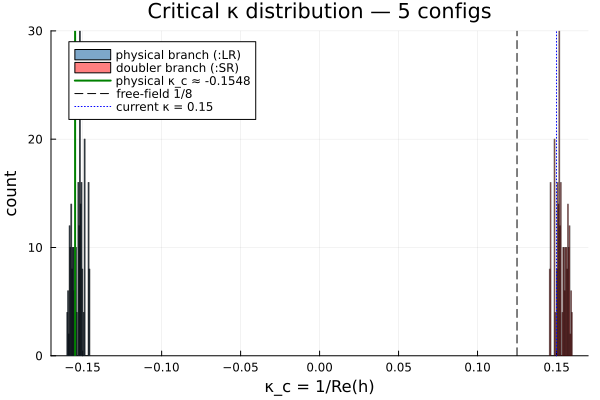

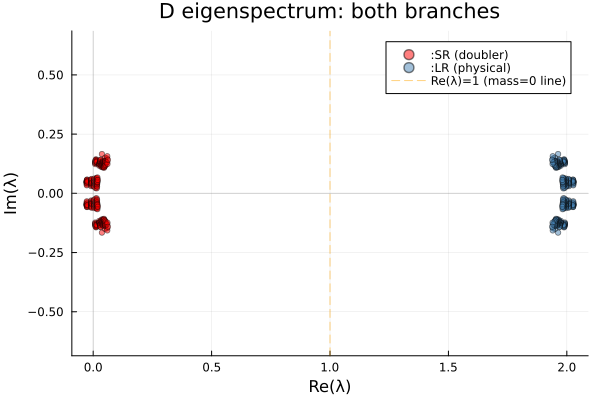

In [12]:
# κ_c 분포 히스토그램
p_kc1 = histogram(κc_LR, bins=40, alpha=0.7, color=:steelblue, label="physical branch (:LR)",
    xlabel="κ_c = 1/Re(h)", ylabel="count",
    title="Critical κ distribution — $(length(gauge_files)) configs")
histogram!(κc_SR, bins=40, alpha=0.5, color=:red, label="doubler branch (:SR)")
vline!([κc_avg], color=:green, linewidth=2, label="physical κ_c ≈ $(round(κc_avg, digits=4))")
vline!([0.125], color=:black, linewidth=1, linestyle=:dash, label="free-field 1/8")
vline!([κ_now], color=:blue, linewidth=1, linestyle=:dot, label="current κ = $κ_now")
display(p_kc1)

# 복소 평면에 :SR과 :LR 모두 표시 + κ_c annotation
all_SR = vcat(all_evals...)
all_LR = vcat(all_evals_LR...)
p_kc2 = scatter(real.(all_SR), imag.(all_SR), markersize=3, alpha=0.5,
    label=":SR (doubler)", color=:red,
    xlabel="Re(λ)", ylabel="Im(λ)",
    title="D eigenspectrum: both branches", aspect_ratio=:equal)
scatter!(real.(all_LR), imag.(all_LR), markersize=3, alpha=0.5,
    label=":LR (physical)", color=:steelblue)
vline!([0], color=:gray, linewidth=1, alpha=0.3, label=nothing)
vline!([1], color=:orange, linewidth=1, linestyle=:dash, alpha=0.5, label="Re(λ)=1 (mass=0 line)")
hline!([0], color=:gray, linewidth=1, alpha=0.3, label=nothing)
display(p_kc2)

## Critical κ — ensemble (β=6, 8³×16)

각 config의 D 고유값에서 `min Re(λ_D)`를 찾아  
$$\kappa_c^{(i)} = \frac{\kappa_{\text{now}}}{1 - \min_j \mathrm{Re}\,\lambda_j^{(i)}}$$  
로 추정. ensemble 평균과 표준오차(SEM)를 계산.


In [13]:
# ensemble κ_c 계산
# - 각 config에서 D의 :SR 고유값 nev_kc개를 구하고
# - κ_c^(i) = κ_now / (1 - min Re λ) 추정

const GAUGE_DIR = "C://Users/_s2220186/Desktop/Julia/gauge"
config_ids   = collect(1:20)              # ← 사용할 config 번호 (조정 가능)
nev_kc       = 8                           # config당 구할 :SR 고유값 개수
κ_now_kc     = params["κ"]
β            = 6.0

κc_list   = Float64[]
λmin_list = Float64[]
used_ids  = Int[]

for cid in config_ids
    gfile = joinpath(GAUGE_DIR, "config_$(cid).jld2")
    if !isfile(gfile)
        @warn "missing $gfile, skip"
        continue
    end
    Ug = load(gfile, "U")
    U  = Initialize_Gaugefields(NC, Nwing, NX, NY, NZ, NT, condition="cold")
    substitute_U!(U, Ug)

    xtmp = Initialize_pseudofermion_fields(U[1], "Wilson", nowing=true)
    D_W  = Dirac_operator(U, xtmp, params)

    evals, _ = compute_D_eigenvalues(D_W, U, nev_kc;
                  krylovdim=max(2nev_kc + 20, 40), tol=1e-7, maxiter=400)

    λmin = minimum(real.(evals))
    kc   = κ_now_kc / (1 - λmin)
    push!(λmin_list, λmin)
    push!(κc_list,   kc)
    push!(used_ids,  cid)
    println("config $cid: min Re(λ) = $(round(λmin, digits=6)),  κ_c ≈ $(round(kc, digits=6))")
end

N = length(κc_list)
μ_kc  = sum(κc_list) / N
σ_kc  = sqrt(sum((κc_list .- μ_kc).^2) / (N - 1))      # sample std
sem   = σ_kc / sqrt(N)                                 # standard error of mean

# Jackknife (보조 추정)
jk_means = [ (sum(κc_list) - κc_list[i]) / (N - 1) for i in 1:N ]
jk_mean  = sum(jk_means) / N
jk_err   = sqrt((N - 1)/N * sum((jk_means .- jk_mean).^2))

println("\n" * "="^58)
println("  Critical κ (β=$β, lattice $(NX)×$(NY)×$(NZ)×$(NT))")
println("="^58)
println("  N configs                = $N")
println("  ⟨κ_c⟩                    = $(round(μ_kc, digits=6))")
println("  sample std σ             = $(round(σ_kc, digits=6))")
println("  standard error (SEM)     = $(round(sem,  digits=6))")
println("  jackknife mean           = $(round(jk_mean, digits=6))")
println("  jackknife error          = $(round(jk_err,  digits=6))")
println("  → κ_c = $(round(μ_kc, digits=5)) ± $(round(sem, digits=5))   (SEM)")
println("="^58)


KrylovKit: 8 converged, 220 iterations, 3486 matvecs
config 1: min Re(λ) = -0.028499,  κ_c ≈ 0.145844
KrylovKit: 2 converged, 400 iterations, 6417 matvecs
config 2: min Re(λ) = -0.008803,  κ_c ≈ 0.148691


┌ Warning: Arnoldi eigsolve stopped without convergence after 400 iterations:
│ * 2 eigenvalues converged
│ * norm of residuals = (1.04e-16, 1.15e-16, 3.25e-05, 6.44e-05, 2.21e-16, 1.18e-16, 3.32e-11, 6.37e-11)
│ * number of operations = 6417
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\ZcdRg\src\eigsolve\arnoldi.jl:172


KrylovKit: 12 converged, 361 iterations, 5796 matvecs
config 3: min Re(λ) = 0.001696,  κ_c ≈ 0.150255
KrylovKit: 10 converged, 205 iterations, 3300 matvecs
config 4: min Re(λ) = 0.009495,  κ_c ≈ 0.151438
KrylovKit: 2 converged, 400 iterations, 6424 matvecs


┌ Warning: Arnoldi eigsolve stopped without convergence after 400 iterations:
│ * 2 eigenvalues converged
│ * norm of residuals = (1.93e-16, 1.87e-16, 4.30e-06, 2.49e-05, 2.95e-07, 9.06e-06, 1.12e-16, 3.79e-16)
│ * number of operations = 6424
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\ZcdRg\src\eigsolve\arnoldi.jl:172


config 5: min Re(λ) = 0.014327,  κ_c ≈ 0.15218
KrylovKit: 11 converged, 281 iterations, 4517 matvecs
config 6: min Re(λ) = 0.016505,  κ_c ≈ 0.152517
KrylovKit: 16 converged, 273 iterations, 4391 matvecs
config 7: min Re(λ) = 0.017442,  κ_c ≈ 0.152663
KrylovKit: 10 converged, 219 iterations, 3439 matvecs
config 8: min Re(λ) = 0.020495,  κ_c ≈ 0.153139
KrylovKit: 8 converged, 185 iterations, 2975 matvecs
config 9: min Re(λ) = 0.02067,  κ_c ≈ 0.153166
KrylovKit: 11 converged, 249 iterations, 4005 matvecs
config 10: min Re(λ) = 0.023726,  κ_c ≈ 0.153645
KrylovKit: 13 converged, 370 iterations, 5933 matvecs
config 11: min Re(λ) = 0.022809,  κ_c ≈ 0.153501
KrylovKit: 7 converged, 400 iterations, 6319 matvecs
config 12: min Re(λ) = 0.022765,  κ_c ≈ 0.153494

┌ Warning: Arnoldi eigsolve stopped without convergence after 400 iterations:
│ * 7 eigenvalues converged
│ * norm of residuals = (4.54e-12, 1.83e-16, 3.19e-15, 1.28e-08, 1.65e-16, 2.06e-16, 1.58e-10, 1.47e-05)
│ * number of operations = 6319
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\ZcdRg\src\eigsolve\arnoldi.jl:172



KrylovKit: 11 converged, 132 iterations, 2129 matvecs
config 13: min Re(λ) = 0.022831,  κ_c ≈ 0.153505
KrylovKit: 8 converged, 159 iterations, 2564 matvecs
config 14: min Re(λ) = 0.022532,  κ_c ≈ 0.153458
KrylovKit: 9 converged, 92 iterations, 1495 matvecs
config 15: min Re(λ) = 0.023721,  κ_c ≈ 0.153645
KrylovKit: 14 converged, 304 iterations, 4881 matvecs
config 16: min Re(λ) = 0.028347,  κ_c ≈ 0.154376
KrylovKit: 8 converged, 386 iterations, 6199 matvecs
config 17: min Re(λ) = 0.029378,  κ_c ≈ 0.15454
KrylovKit: 2 converged, 400 iterations, 6424 matvecs
config 18: min Re(λ) = 0.027388,  κ_c ≈ 0.154224

┌ Warning: Arnoldi eigsolve stopped without convergence after 400 iterations:
│ * 2 eigenvalues converged
│ * norm of residuals = (1.51e-09, 1.73e-10, 1.21e-04, 1.73e-04, 1.26e-16, 2.62e-16, 4.42e-10, 3.58e-09)
│ * number of operations = 6424
└ @ KrylovKit C:\Users\_s2220186\.julia\packages\KrylovKit\ZcdRg\src\eigsolve\arnoldi.jl:172



KrylovKit: 15 converged, 326 iterations, 5207 matvecs
config 19: min Re(λ) = 0.027438,  κ_c ≈ 0.154232
KrylovKit: 10 converged, 179 iterations, 2888 matvecs
config 20: min Re(λ) = 0.027618,  κ_c ≈ 0.15426

  Critical κ (β=6.0, lattice 8×8×8×16)
  N configs                = 20
  ⟨κ_c⟩                    = 0.152639
  sample std σ             = 0.002163
  standard error (SEM)     = 0.000484
  jackknife mean           = 0.152639
  jackknife error          = 0.000484
  → κ_c = 0.15264 ± 0.00048   (SEM)


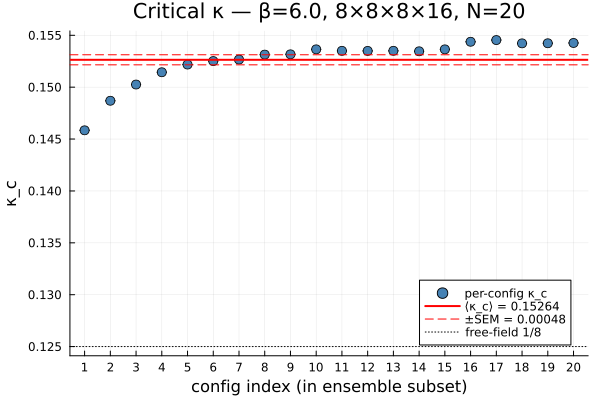

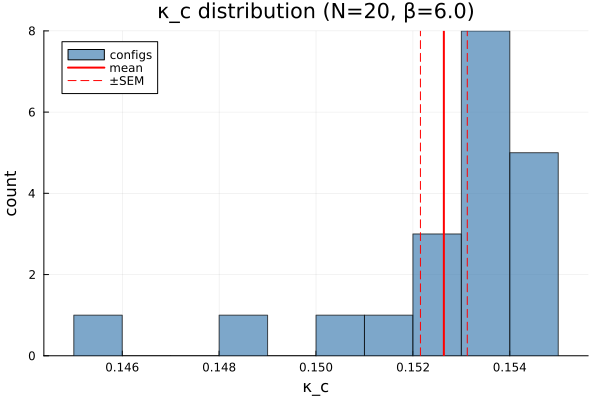

In [14]:
# 시각화: config별 κ_c + 평균/오차 밴드
xs = 1:N

p_kc = scatter(xs, κc_list,
    yerror = fill(0.0, N),                # 개별 점은 단일값 (시각용)
    markersize=5, color=:steelblue, label="per-config κ_c",
    xlabel="config index (in ensemble subset)", ylabel="κ_c",
    title="Critical κ — β=$β, $(NX)×$(NY)×$(NZ)×$(NT), N=$N",
    xticks=(xs, string.(used_ids)))

# 평균선 + ±SEM 밴드
hline!([μ_kc], color=:red, linewidth=2, label="⟨κ_c⟩ = $(round(μ_kc,digits=5))")
hline!([μ_kc + sem, μ_kc - sem], color=:red, linewidth=1, linestyle=:dash, label="±SEM = $(round(sem,digits=5))")

# free-field 기준선
hline!([0.125], color=:black, linewidth=1, linestyle=:dot, label="free-field 1/8")
display(p_kc)

# κ_c 분포 히스토그램
p_kc_hist = histogram(κc_list, bins=max(8, N÷2), alpha=0.7, color=:steelblue,
    xlabel="κ_c", ylabel="count",
    title="κ_c distribution (N=$N, β=$β)",
    label="configs")
vline!([μ_kc], color=:red, linewidth=2, label="mean")
vline!([μ_kc + sem, μ_kc - sem], color=:red, linewidth=1, linestyle=:dash, label="±SEM")
display(p_kc_hist)
